# scikit-learn Perceptron — Imbalanced, Non-Separable Data

80/20 class imbalance with 10% label noise: why accuracy (0.80) hides a weak minority-class recall (0.50); precision, recall, F1 and the decision boundary.

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.datasets import make_classification
from sklearn import datasets

# 2.b.1

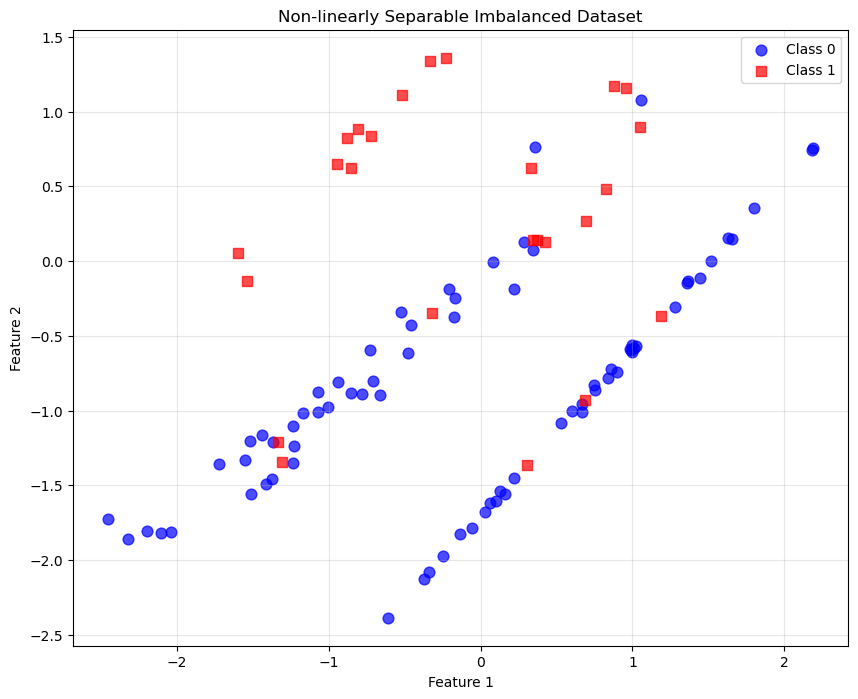

In [15]:
X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=2,
    weights=[0.8, 0.2],
    flip_y=0.1,
    class_sep=0.8,
    random_state=42
)

plt.figure(figsize=(10, 8))
plt.scatter(X[y == 0, 0], X[y == 0, 1], c='blue', marker='o', s=60, label='Class 0', alpha=0.7)
plt.scatter(X[y == 1, 0], X[y == 1, 1], c='red', marker='s', s=60, label='Class 1', alpha=0.7)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Non-linearly Separable Imbalanced Dataset')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2.b.2

In [16]:
y_shape = y.reshape(100,1)
X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.3,random_state=420)

# 2.b.3

In [17]:
from sklearn.linear_model import Perceptron

clf = Perceptron()

clf.fit(X_train,Y_train)

y_pred = clf.predict(X_test)

print("Classifier Weights: ", clf.coef_)
print("Classifier Constant:", clf.intercept_)

Classifier Weights:  [[-1.95583641  3.50142846]]
Classifier Constant: [0.]


# 2.b.4

In [18]:
from sklearn.metrics import f1_score, precision_score, recall_score, accuracy_score, confusion_matrix, classification_report

In [19]:
print(f1_score(Y_test,y_pred))

0.625


In [20]:
print(precision_score(Y_test,y_pred))

0.8333333333333334


In [21]:
print(recall_score(Y_test,y_pred))

0.5


In [22]:
print(accuracy_score(Y_test, y_pred))

0.8


In [23]:
print(classification_report(Y_test, y_pred))

              precision    recall  f1-score   support

           0       0.79      0.95      0.86        20
           1       0.83      0.50      0.62        10

    accuracy                           0.80        30
   macro avg       0.81      0.72      0.74        30
weighted avg       0.81      0.80      0.78        30



In [24]:
print(confusion_matrix(Y_test, y_pred))

[[19  1]
 [ 5  5]]


# 2.b.5

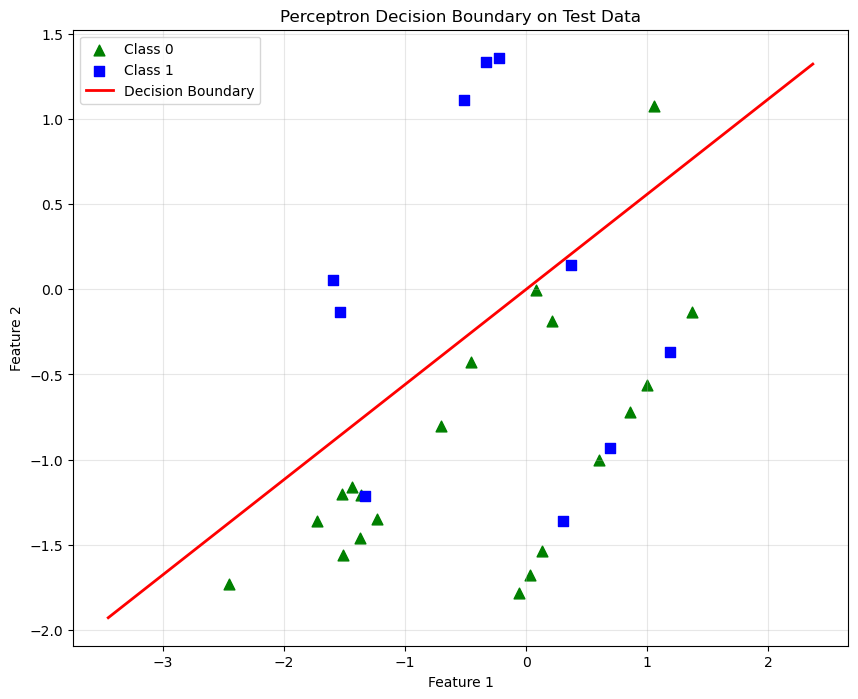

In [25]:
plt.figure(figsize=(10, 8))

plt.scatter(X_test[Y_test == 0, 0], X_test[Y_test == 0, 1], c='green', marker='^', s=60, label='Class 0')
plt.scatter(X_test[Y_test == 1, 0], X_test[Y_test == 1, 1], c='blue', marker='s', s=60, label='Class 1')

xx = np.linspace(X_test[:, 0].min()-1, X_test[:, 0].max()+1, 100)
yy = (-clf.coef_[0][0] * xx - clf.intercept_[0]) / clf.coef_[0][1]
plt.plot(xx, yy, 'r-', linewidth=2, label='Decision Boundary')

plt.grid(True, alpha=0.3)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('Perceptron Decision Boundary on Test Data')
plt.legend()

plt.show()